# DELIMITACIÓN DE LA PISCINA, CORCHERAS Y LIMPIEZA DE RUIDO — VISTA SUPERIOR LATERAL (ISL)

Juan David Hurtado Molano

Laura Sofía Salamanca Barrera

Tercera entrega. Tres objetivos sobre la vista **ISL** (superior lateral):

1. **Delimitar la piscina**: encontrar su contorno con rectas y esquinas calculadas por intersección.
2. **Identificar las corcheras** con la transformada de Hough.
3. **Quitar el ruido**: corcheras, guías del fondo, gráficos de TV y todo lo que queda fuera de la piscina.

**Idea central.** En el mundo, las corcheras, las guías del fondo y los dos bordes largos de la piscina son rectas paralelas. Por la perspectiva, en la imagen todas se cortan en un mismo punto: el **punto de fuga**. Si encontramos ese punto como la intersección de las rectas que entrega Hough:

* cada carril queda descrito con **un solo número** (la recta que une el punto de fuga con un punto de la imagen),
* todo segmento que **no** apunte al punto de fuga es ruido: gráficos de TV, la línea del récord mundial (WR), los banderines de espalda,
* se puede "enderezar" la imagen para que todos los carriles queden horizontales, y ahí quitar las corcheras es mucho más fácil.

Pipeline:

| Paso | Qué hace | Herramienta |
|---|---|---|
| 1 | Máscara de agua y ROI de piscina | `detector_color.segmentar_agua` (primera entrega) + morfología |
| 2 | Bordes limpios | Canny **sobre la máscara**, no sobre el gris |
| 3 | Punto de fuga | `HoughLinesP` + intersección de rectas en coordenadas homogéneas + RANSAC |
| 4 | Rectificación | cada recta que pasa por el punto de fuga se vuelve una fila horizontal |
| 5 | Delimitación | borde lejano, paredes de cabecera (RANSAC) y **esquinas por intersección** |
| 6 | Corcheras | perfiles por fila → rectas infinitas por el punto de fuga |
| 7 | Quitar ruido | guías y gráficos fuera → corcheras sobre fondo negro |

In [1]:
from __future__ import annotations

import sys
import time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "images").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import detector_color as dc  # máscara de agua de la primera entrega

IMAGES_DIR = ROOT / "data" / "images"
VISTA = "ISL"
rutas = sorted((IMAGES_DIR / VISTA).glob("*.jpg"))
imagenes = {r.stem: cv2.imread(str(r)) for r in rutas}
print(f"{VISTA}: {len(rutas)} imágenes de {next(iter(imagenes.values())).shape}")

%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["figure.dpi"] = 72
plt.rcParams["savefig.dpi"] = 72

rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
EJEMPLOS = ["ISL_00204", "ISL_01224", "ISL_00408", "ISL_02448"]  # pared a la der., pared a la izq., sin pared, sin pared + oficiales

ISL: 20 imágenes de (1080, 1920, 3)


## 1. Máscara de agua y ROI de la piscina

Se reutiliza tal cual `dc.segmentar_agua(img, "ISL")` de la primera entrega: canal H entre 90 y 110, votación 5×5 y mediana 3×3 (blanco = agua). Las corcheras, guías, nadadores y gráficos quedan en negro.

Sobre esa máscara se arma la **ROI de piscina**: cierre morfológico, componente conexa más grande y relleno de huecos internos. La ROI no es todavía la delimitación final (incluye, por ejemplo, el letrero azul de "Rio 2016" de la pared del fondo porque tiene el mismo tono que el agua); sirve para que Canny y Hough no miren al público ni al deck.

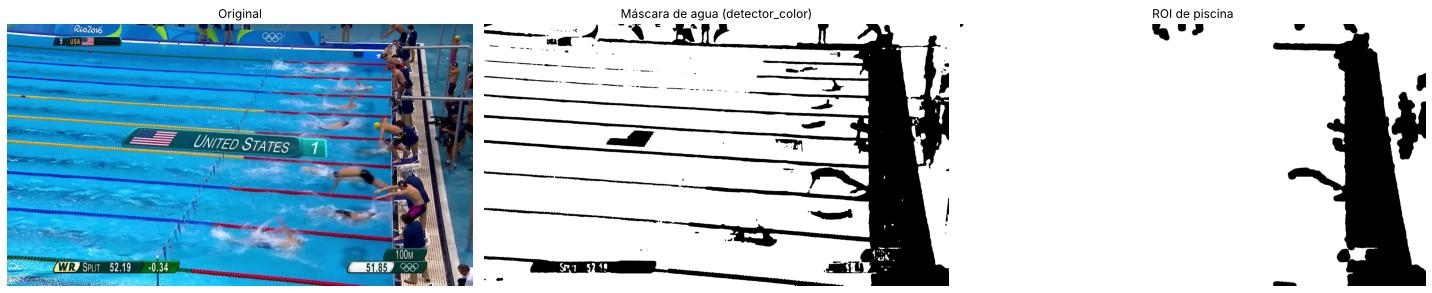

In [2]:
def roi_piscina(agua: np.ndarray, kernel: int = 25) -> np.ndarray:
    # Cierre + componente conexa más grande + relleno de huecos internos.
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))
    cerrado = cv2.morphologyEx(agua, cv2.MORPH_CLOSE, k)
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(cerrado, connectivity=8)
    if n <= 1:
        return cerrado
    mayor = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    blob = ((etiquetas == mayor) * 255).astype(np.uint8)
    contornos, _ = cv2.findContours(blob, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    relleno = np.zeros_like(blob)
    cv2.drawContours(relleno, contornos, -1, 255, -1)
    return relleno


img = imagenes[EJEMPLOS[0]]
agua = dc.segmentar_agua(img, VISTA)
roi = roi_piscina(agua)

fig, ax = plt.subplots(1, 3, figsize=(20, 4.2))
ax[0].imshow(rgb(img)); ax[0].set_title("Original")
ax[1].imshow(agua, cmap="gray"); ax[1].set_title("Máscara de agua (detector_color)")
ax[2].imshow(roi, cmap="gray"); ax[2].set_title("ROI de piscina")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Canny limpio: ¿sobre el gris o sobre la máscara?

El ruido de Canny dentro de la piscina viene del **brillo** del agua: cada ola o reflejo cambia mucho la intensidad, pero casi nada el **tono**. La máscara de agua se construye con el tono, así que dentro del agua es un bloque sólido de 255 sin textura. Se comparan tres entradas para Canny, todas recortadas a la ROI:

1. **Gris** de la imagen (lo clásico).
2. **Gris con el agua "apagada"**: los píxeles que la máscara marca como agua se reemplazan por el gris mediano del agua. Se conserva el gradiente real en corcheras y nadadores, pero el oleaje desaparece.
3. **Máscara binaria**: los únicos bordes posibles son las fronteras agua / no-agua.

Para Hough se usa la opción 3: entrega bordes nítidos de un píxel justo en los contornos de corcheras, guías y paredes.

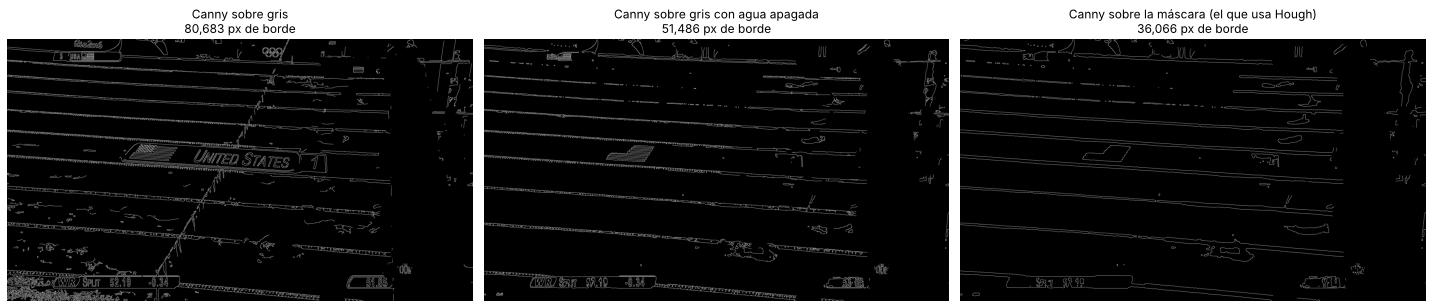

Canny sobre gris                              promedio en las 20 imágenes:    73,950 px de borde
Canny sobre gris con agua apagada             promedio en las 20 imágenes:    48,467 px de borde
Canny sobre la máscara (el que usa Hough)     promedio en las 20 imágenes:    37,534 px de borde


In [3]:
def bordes_canny(agua: np.ndarray, roi: np.ndarray, bajo: int = 50, alto: int = 150) -> np.ndarray:
    # Canny sobre la máscara de agua, recortado a la ROI (erosionada para no tomar el borde de la ROI misma).
    bordes = cv2.Canny(agua, bajo, alto)
    return cv2.bitwise_and(bordes, bordes, mask=cv2.erode(roi, np.ones((9, 9), np.uint8)))


def canny_variantes(img, agua, roi):
    gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    apagado = gris.copy()
    apagado[agua > 0] = int(np.median(gris[agua > 0]))
    m = cv2.erode(roi, np.ones((9, 9), np.uint8))
    return {
        "Canny sobre gris": cv2.bitwise_and(cv2.Canny(gris, 50, 150), m),
        "Canny sobre gris con agua apagada": cv2.bitwise_and(cv2.Canny(apagado, 50, 150), m),
        "Canny sobre la máscara (el que usa Hough)": bordes_canny(agua, roi),
    }


variantes = canny_variantes(img, agua, roi)
fig, ax = plt.subplots(1, 3, figsize=(20, 4.2))
for a, (titulo, b) in zip(ax, variantes.items()):
    a.imshow(b, cmap="gray"); a.set_title(f"{titulo}\n{int((b > 0).sum()):,} px de borde"); a.axis("off")
plt.tight_layout(); plt.show()

conteos = []
for im in imagenes.values():
    ag = dc.segmentar_agua(im, VISTA)
    conteos.append([int((b > 0).sum()) for b in canny_variantes(im, ag, roi_piscina(ag)).values()])
conteos = np.array(conteos)
for titulo, media in zip(variantes, conteos.mean(0)):
    print(f"{titulo:45s} promedio en las 20 imágenes: {media:9,.0f} px de borde")

## 3. Hough y punto de fuga (intersección de rectas)

`cv2.HoughLinesP` sobre los bordes de la máscara entrega segmentos. Cada segmento se convierte en una **recta infinita** en coordenadas homogéneas:

$$\ell = p_1 \times p_2, \qquad p_i = (x_i, y_i, 1)$$

y la **intersección** de dos rectas es otro producto cruz: $v = \ell_1 \times \ell_2$. Si las rectas son paralelas en la imagen, $v$ sale con tercera coordenada 0 (un punto en el infinito), así que el mismo código sirve para vistas sin perspectiva (como IS).

**RANSAC**: se toman al azar dos segmentos casi horizontales, se intersectan para proponer un punto de fuga $v$, y se cuenta cuánta longitud de segmentos "apunta" a $v$ (ángulo entre el segmento y la dirección hacia $v$ menor a 1.5°). Gana el $v$ con más soporte y se refina por mínimos cuadrados con todas las rectas que lo apoyan (vector singular más chico de la matriz de rectas, ponderada por longitud).

Los segmentos que **no** apuntan al punto de fuga (en rojo) son justamente el ruido: la línea del WR, los banderines, los bordes de los gráficos y la pared de cabecera.

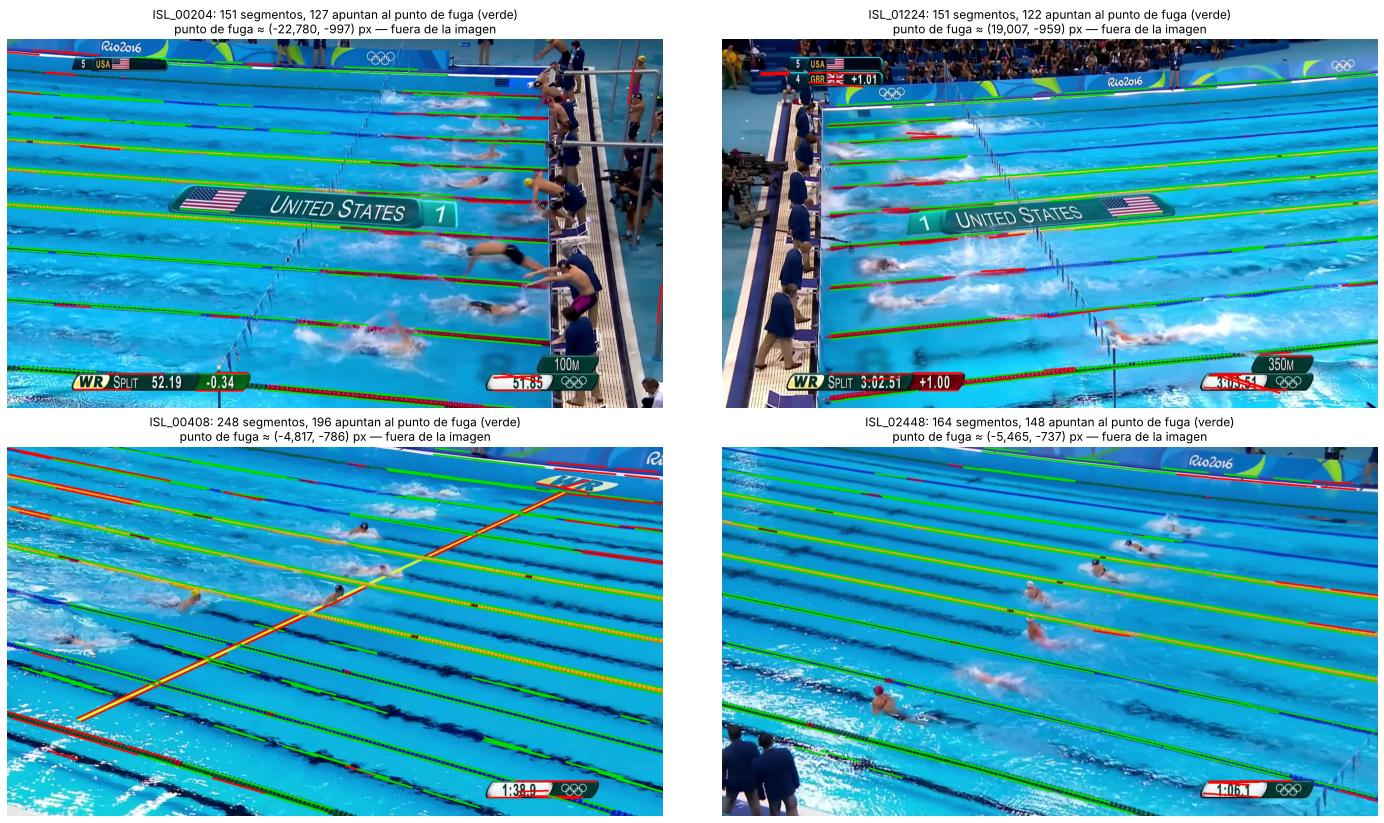

In [4]:
def hough_segmentos(bordes, umbral=60, longitud_min=80, hueco_max=20):
    L = cv2.HoughLinesP(bordes, 1, np.pi / 180, umbral, minLineLength=longitud_min, maxLineGap=hueco_max)
    return L.reshape(-1, 4).astype(float) if L is not None else np.empty((0, 4))


def rectas_homogeneas(L):
    p1 = np.c_[L[:, :2], np.ones(len(L))]
    p2 = np.c_[L[:, 2:], np.ones(len(L))]
    l = np.cross(p1, p2)
    return l / np.linalg.norm(l[:, :2], axis=1, keepdims=True)


def error_angular(L, v):
    # Ángulo (grados) entre cada segmento y la dirección desde su punto medio hacia v.
    medio = (L[:, :2] + L[:, 2:]) / 2
    d = L[:, 2:] - L[:, :2]
    d = d / np.linalg.norm(d, axis=1, keepdims=True)
    t = (v[:2] / v[2] - medio) if abs(v[2]) > 1e-9 else np.tile(v[:2], (len(L), 1))
    t = t / (np.linalg.norm(t, axis=1, keepdims=True) + 1e-12)
    return np.degrees(np.arccos(np.clip(np.abs((d * t).sum(1)), 0, 1)))


def punto_fuga(L, tol=1.5, iteraciones=2000, angulo_max=35, semilla=0):
    rng = np.random.default_rng(semilla)
    lon = np.hypot(L[:, 2] - L[:, 0], L[:, 3] - L[:, 1])
    l = rectas_homogeneas(L)
    ang = np.degrees(np.arctan2(L[:, 3] - L[:, 1], L[:, 2] - L[:, 0]))
    candidatos = np.where(np.abs((ang + 90) % 180 - 90) < angulo_max)[0]
    mejor, puntaje = None, -1
    for _ in range(iteraciones):
        i, j = rng.choice(candidatos, 2, replace=False)
        v = np.cross(l[i], l[j])                       # intersección de dos rectas
        if np.linalg.norm(v) < 1e-12:
            continue
        v /= np.linalg.norm(v)
        s = lon[error_angular(L, v) < tol].sum()
        if s > puntaje:
            puntaje, mejor = s, v
    inliers = error_angular(L, mejor) < tol
    _, _, Vt = np.linalg.svd(l[inliers] * lon[inliers, None])   # refinamiento por mínimos cuadrados
    v = Vt[-1]
    if v[2] < 0:
        v = -v
    return v, error_angular(L, v) < tol


fig, axs = plt.subplots(2, 2, figsize=(20, 11.5))
for a, nombre in zip(axs.ravel(), EJEMPLOS):
    im = imagenes[nombre]
    ag = dc.segmentar_agua(im, VISTA)
    L = hough_segmentos(bordes_canny(ag, roi_piscina(ag)))
    v, inl = punto_fuga(L)
    out = im.copy()
    for (x1, y1, x2, y2), k in zip(L.astype(int), inl):
        cv2.line(out, (x1, y1), (x2, y2), (0, 220, 0) if k else (0, 0, 255), 4)
    vx, vy = v[:2] / v[2]
    a.imshow(rgb(out)); a.axis("off")
    a.set_title(f"{nombre}: {len(L)} segmentos, {inl.sum()} apuntan al punto de fuga (verde)\n"
                f"punto de fuga ≈ ({vx:,.0f}, {vy:,.0f}) px — fuera de la imagen")
plt.tight_layout(); plt.show()

## 4. Rectificación: un carril = una fila

Toda recta que pasa por el punto de fuga $v$ queda identificada por un número $r$: la altura a la que corta la columna central $x_{ref}=W/2$. Para un píxel $(x, y)$:

$$r = v_y + (y - v_y)\,\frac{x_{ref} - v_x}{x - v_x}$$

Construyendo una imagen nueva cuya fila $r$ contiene los píxeles de esa recta (con `cv2.remap`), **todas las corcheras, guías y bordes largos quedan horizontales**, y como dos carriles vecinos siempre están entre las mismas dos rectas, cada carril ocupa una franja de alto constante de punta a punta. Es la misma "votación direccional" de `detector_color.py`, pero ahora en la dirección exacta de los carriles en cada punto de la imagen, no con un kernel fijo.

La transformación es invertible: cualquier máscara calculada en el rectificado se devuelve a la imagen original con otro `remap`.

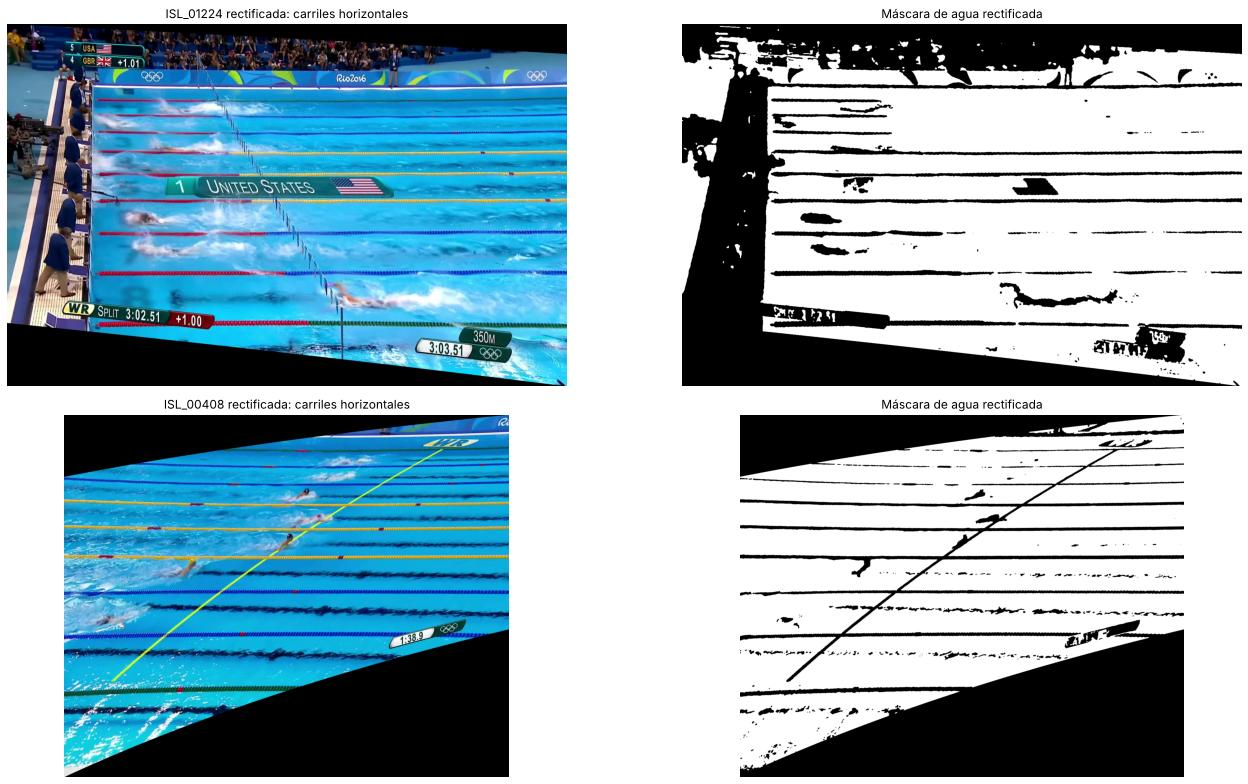

In [5]:
def _y_en_rayo(r, x, v, x_ref):
    if abs(v[2]) < 1e-9 * np.linalg.norm(v):                # punto de fuga en el infinito
        return r + (v[1] / v[0]) * (x - x_ref)
    vx, vy = v[0] / v[2], v[1] / v[2]
    return vy + (r - vy) * (x - vx) / (x_ref - vx)


def _r_de_punto(x, y, v, x_ref):
    if abs(v[2]) < 1e-9 * np.linalg.norm(v):
        return y - (v[1] / v[0]) * (x - x_ref)
    vx, vy = v[0] / v[2], v[1] / v[2]
    return vy + (y - vy) * (x_ref - vx) / (x - vx)


class Rectificador:
    # Lleva la imagen al espacio (x, r), donde cada fila es una recta que pasa por el punto de fuga.

    def __init__(self, v, shape):
        self.v = np.asarray(v, float)
        self.H, self.W = shape[:2]
        self.x_ref = self.W / 2
        rs = [_r_de_punto(x, y, self.v, self.x_ref) for x in (0, self.W - 1) for y in (0, self.H - 1)]
        self.r0, r1 = int(np.floor(min(rs))), int(np.ceil(max(rs)))
        X, R = np.meshgrid(np.arange(self.W, dtype=np.float32), np.arange(self.r0, r1, dtype=np.float32))
        self._mx, self._my = X, _y_en_rayo(R, X, self.v, self.x_ref).astype(np.float32)
        Xi, Yi = np.meshgrid(np.arange(self.W, dtype=np.float32), np.arange(self.H, dtype=np.float32))
        self._ix, self._iy = Xi, (_r_de_punto(Xi, Yi, self.v, self.x_ref) - self.r0).astype(np.float32)
        self.validos = self.a_rect(np.full((self.H, self.W), 255, np.uint8), cv2.INTER_NEAREST) > 0

    def a_rect(self, img, interp=cv2.INTER_LINEAR):
        return cv2.remap(img, self._mx, self._my, interp, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    def a_imagen(self, img, interp=cv2.INTER_NEAREST):
        return cv2.remap(img, self._ix, self._iy, interp, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    def recta_de_fila(self, fila):
        # Recta homogénea (a, b, c) de la imagen original que corresponde a una fila del rectificado.
        l = np.cross([self.x_ref, fila + self.r0, 1.0], self.v)
        return l / np.linalg.norm(l[:2])

    def punto(self, x, fila):
        return np.array([x, _y_en_rayo(fila + self.r0, x, self.v, self.x_ref)])


fig, axs = plt.subplots(2, 2, figsize=(20, 11))
for fila_ax, nombre in zip(axs, EJEMPLOS[1:3]):
    im = imagenes[nombre]
    ag = dc.segmentar_agua(im, VISTA)
    v, _ = punto_fuga(hough_segmentos(bordes_canny(ag, roi_piscina(ag))))
    rect = Rectificador(v, im.shape)
    fila_ax[0].imshow(rgb(rect.a_rect(im))); fila_ax[0].set_title(f"{nombre} rectificada: carriles horizontales")
    fila_ax[1].imshow(rect.a_rect(ag, cv2.INTER_NEAREST), cmap="gray"); fila_ax[1].set_title("Máscara de agua rectificada")
    for a in fila_ax: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Delimitación de la piscina con rectas e intersecciones

La piscina se delimita con cuatro rectas y sus cuatro esquinas:

* **Lados largos** (paralelos a los carriles, pasan por el punto de fuga, son filas del rectificado):
  * *Borde lejano*: dentro de las filas con agua, la fila con más píxeles blancos de la mitad superior. Es la **canaleta** blanca de la pared del fondo; por encima está el letrero "Rio 2016", que tiene casi el mismo tono que el agua y por eso la máscara sola no lo separa. Si no hay canaleta visible, se usa la primera fila con agua.
  * *Borde cercano*: la última fila con agua (en ISL la pared cercana casi nunca sale en cuadro).
* **Lados cortos** (paredes de cabecera, **no** pasan por el punto de fuga): en cada fila del rectificado se busca la corrida de agua más larga (rellenando huecos menores a 80 px, que son nadadores o banderines). Si esa corrida termina antes del borde de la imagen, ahí está la pared. Esos puntos, llevados a la imagen original, se ajustan con **RANSAC + `fitLine`**. Si no hay suficientes puntos, ese lado es el borde de la imagen ($x=0$ o $x=W-1$), que también es una recta.
* **Esquinas** = intersección (producto cruz) de cada lado largo con cada lado corto. El polígono de las cuatro esquinas, recortado a la imagen, es la máscara de piscina.

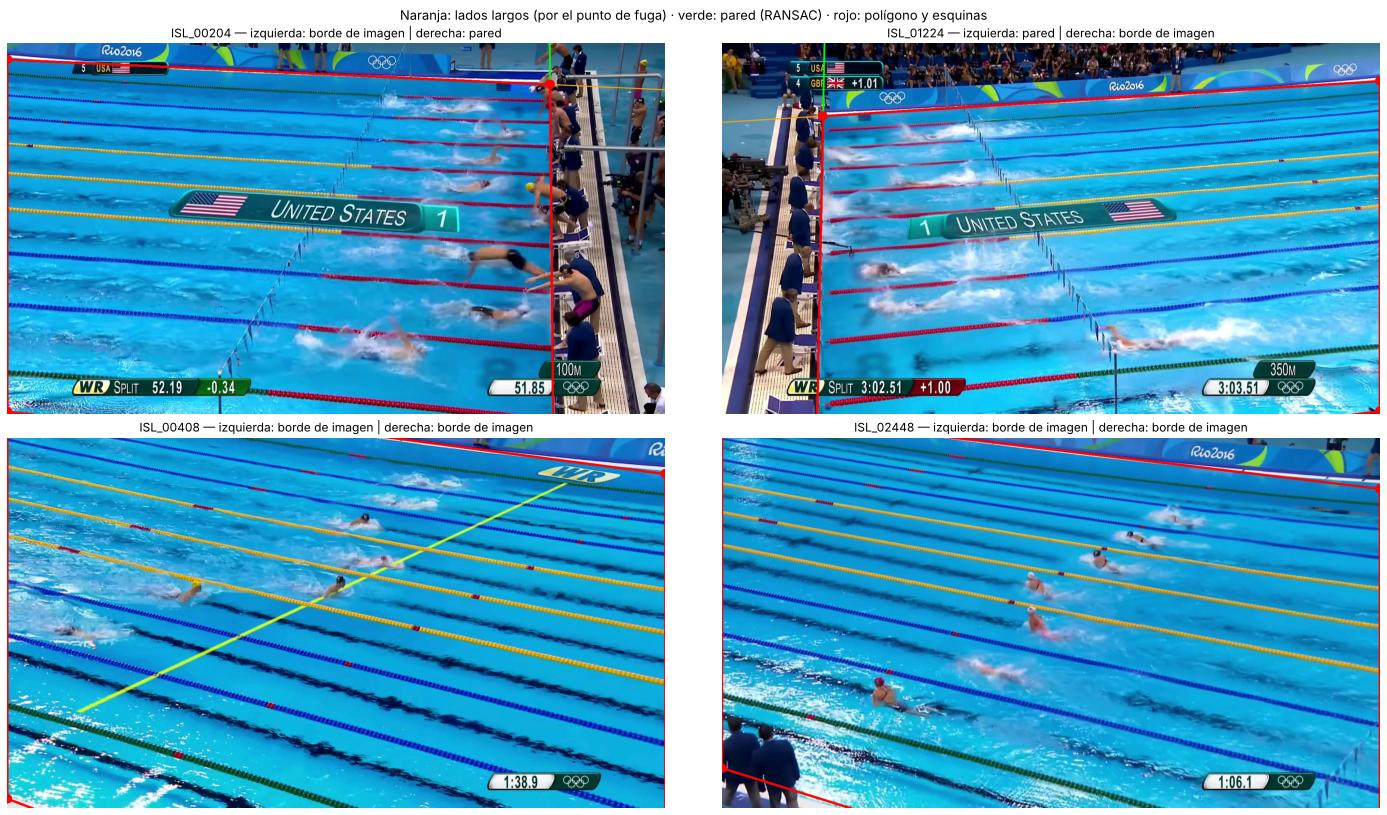

In [6]:
def _corridas(b):
    d = np.diff(np.r_[0, b.astype(np.int8), 0])
    return np.flatnonzero(d == 1), np.flatnonzero(d == -1)       # inicios, fines (exclusivos)


def _cerrar_1d(b, hueco):
    ini, fin = _corridas(b)
    out = b.copy()
    for a, z in zip(fin[:-1], ini[1:]):
        if z - a <= hueco:
            out[a:z] = True
    return out


def ajustar_recta_ransac(P, tol=6, iteraciones=500, semilla=0):
    rng = np.random.default_rng(semilla)
    mejor = None
    for _ in range(iteraciones):
        i, j = rng.choice(len(P), 2, replace=False)
        l = np.cross([*P[i], 1], [*P[j], 1])
        if np.linalg.norm(l[:2]) < 1e-9:
            continue
        l = l / np.linalg.norm(l[:2])
        inl = np.abs(P @ l[:2] + l[2]) < tol
        if mejor is None or inl.sum() > mejor.sum():
            mejor = inl
    vx, vy, x0, y0 = cv2.fitLine(P[mejor].astype(np.float32), cv2.DIST_HUBER, 0, 0.01, 0.01).ravel()
    l = np.cross([x0, y0, 1], [x0 + vx, y0 + vy, 1])
    return l / np.linalg.norm(l[:2]), mejor


def interseccion(l1, l2):
    p = np.cross(l1, l2)
    return p[:2] / p[2]


def delimitar_piscina(rect, img_r, agua_r, roi_r, frac_min=0.5, hueco=80, margen=25,
                      min_filas=0.25, blanco_min=0.2):
    val = rect.validos
    cnt = val.sum(1)
    frac = np.where(cnt > 50, ((roi_r > 0) & val).sum(1) / np.maximum(cnt, 1), 0)
    ini, fin = _corridas(_cerrar_1d(frac > frac_min, 15))
    k = np.argmax(fin - ini)
    f_sup, f_inf = ini[k], fin[k] - 1

    # borde lejano: canaleta blanca
    hsv = cv2.cvtColor(img_r, cv2.COLOR_BGR2HSV)
    blanco = (hsv[..., 1] < 60) & (hsv[..., 2] > 200) & val
    frac_blanco = np.where(cnt > 50, blanco.sum(1) / np.maximum(cnt, 1), 0)
    mitad = (f_sup + f_inf) // 2
    if frac_blanco[f_sup:mitad].size and frac_blanco[f_sup:mitad].max() > blanco_min:
        f_sup += int(np.argmax(frac_blanco[f_sup:mitad]))

    # paredes de cabecera: final de la corrida de agua más larga de cada fila
    puntos = {"izq": [], "der": []}
    for f in range(f_sup, f_inf + 1):
        xs = np.flatnonzero(val[f])
        if len(xs) < 100:
            continue
        ini, fin = _corridas(_cerrar_1d((agua_r[f] > 0) & val[f], hueco))
        if len(ini) == 0:
            continue
        m = np.argmax(fin - ini)
        if fin[m] - ini[m] < 0.3 * len(xs):
            continue
        if ini[m] > xs[0] + margen:
            puntos["izq"].append(rect.punto(ini[m], f))
        if fin[m] - 1 < xs[-1] - margen:
            puntos["der"].append(rect.punto(fin[m] - 1, f))

    minimo = max(20, min_filas * (f_inf - f_sup + 1))
    lados = {}
    for lado, borde in (("izq", np.array([1.0, 0, 0])), ("der", np.array([1.0, 0, -(rect.W - 1)]))):
        lados[lado] = ("borde de imagen", borde)
        P = np.array(puntos[lado])
        if len(P) >= minimo:
            l, inl = ajustar_recta_ransac(P)
            if inl.sum() >= minimo:
                lados[lado] = ("pared", l)

    sup, inf = rect.recta_de_fila(f_sup), rect.recta_de_fila(f_inf)
    esquinas = np.array([interseccion(sup, lados["izq"][1]), interseccion(sup, lados["der"][1]),
                         interseccion(inf, lados["der"][1]), interseccion(inf, lados["izq"][1])])
    mascara = np.zeros((rect.H, rect.W), np.uint8)
    cv2.fillPoly(mascara, [np.round(esquinas).astype(np.int32)], 255)
    return dict(f_sup=f_sup, f_inf=f_inf, sup=sup, inf=inf, lados=lados, esquinas=esquinas,
                mascara=mascara, frac=frac, frac_blanco=frac_blanco, puntos=puntos)


def dibujar_recta(img, l, color, grosor=2):
    a, b, c = l
    H, W = img.shape[:2]
    if abs(b) > abs(a):
        p1, p2 = (0, int(round(-c / b))), (W - 1, int(round(-(a * (W - 1) + c) / b)))
    else:
        p1, p2 = (int(round(-c / a)), 0), (int(round(-(b * (H - 1) + c) / a)), H - 1)
    cv2.line(img, p1, p2, color, grosor, cv2.LINE_AA)



fig, axs = plt.subplots(2, 2, figsize=(20, 11.5))
for a, nombre in zip(axs.ravel(), EJEMPLOS):
    im = imagenes[nombre]
    ag = dc.segmentar_agua(im, VISTA); ro = roi_piscina(ag)
    v, _ = punto_fuga(hough_segmentos(bordes_canny(ag, ro)))
    rect = Rectificador(v, im.shape)
    d = delimitar_piscina(rect, rect.a_rect(im), rect.a_rect(ag, cv2.INTER_NEAREST), rect.a_rect(ro, cv2.INTER_NEAREST))
    out = im.copy()
    for lado in ("izq", "der"):
        if d["lados"][lado][0] == "pared":
            dibujar_recta(out, d["lados"][lado][1], (0, 255, 0), 3)
    dibujar_recta(out, d["sup"], (0, 165, 255), 2); dibujar_recta(out, d["inf"], (0, 165, 255), 2)
    cv2.polylines(out, [np.round(d["esquinas"]).astype(np.int32)], True, (0, 0, 255), 6)
    for p in d["esquinas"]:
        cv2.circle(out, tuple(np.int32(p)), 14, (0, 0, 255), -1)
    a.imshow(rgb(out)); a.axis("off")
    a.set_title(f"{nombre} — izquierda: {d['lados']['izq'][0]} | derecha: {d['lados']['der'][0]}")
fig.suptitle("Naranja: lados largos (por el punto de fuga) · verde: pared (RANSAC) · rojo: polígono y esquinas", fontsize=13)
plt.tight_layout(); plt.show()

## 6. Corcheras como rectas infinitas

En el rectificado cada corchera es una fila. Para cada fila, dentro de la piscina, se cuenta la fracción de píxeles que no son agua por tono (H fuera de 90–110) y no son oscuros: las corcheras rojas, amarillas, azules y verdes flotan y se ven con color propio. Cada pico de ese perfil (máximo local con prominencia ≥ 0.12) es una corchera, y su recta en la imagen original es la que une el punto de fuga con esa fila: una **recta infinita**, como en Hough estándar.

Las guías negras del fondo no son líneas que nos interesen, son ruido. Se ubican igual (picos de la fracción de píxeles oscuros) solo para poder borrarlas en el paso 7.

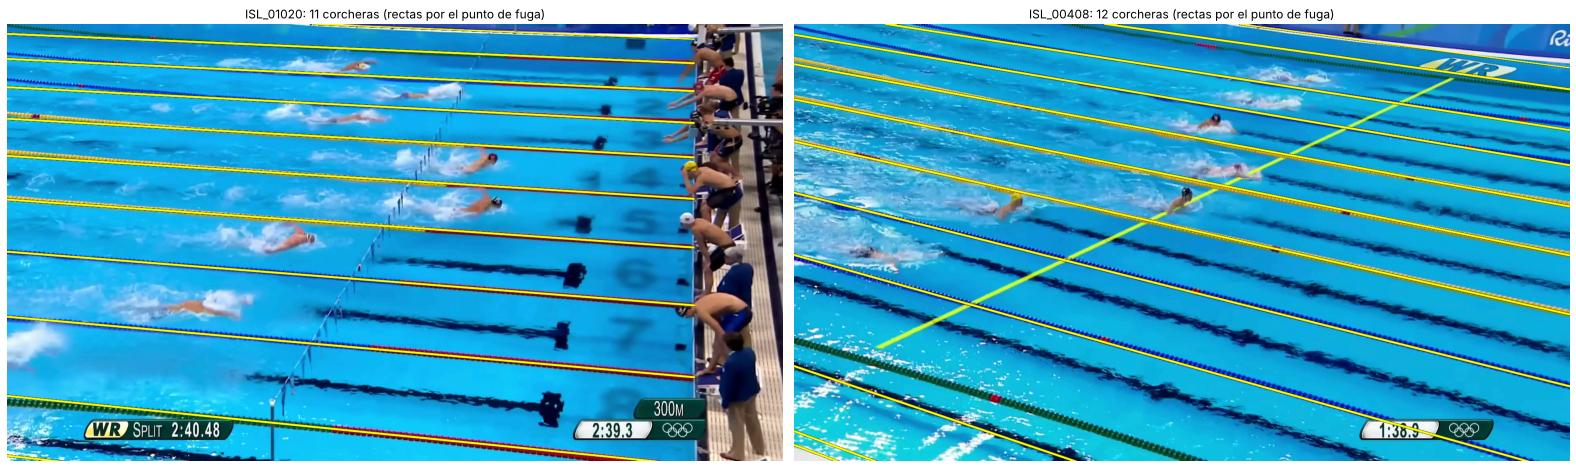

In [7]:
def picos(P, prominencia, distancia):
    # Máximos locales de un perfil 1D con su prominencia y su ancho a media prominencia.
    n = len(P)
    info = []
    for i in range(1, n - 1):
        if not (P[i] > P[i - 1] and P[i] >= P[i + 1]):
            continue
        a = i
        while a > 0 and P[a - 1] <= P[i]:
            a -= 1
        b = i
        while b < n - 1 and P[b + 1] <= P[i]:
            b += 1
        prom = P[i] - max(P[a:i + 1].min(), P[i:b + 1].min())
        if prom < prominencia:
            continue
        mitad = P[i] - prom / 2
        a = i
        while a > 0 and P[a - 1] > mitad:
            a -= 1
        b = i
        while b < n - 1 and P[b + 1] > mitad:
            b += 1
        info.append((i, prom, b - a + 1))
    elegidos = []
    for t in sorted(info, key=lambda t: -P[t[0]]):
        if all(abs(t[0] - e[0]) >= distancia for e in elegidos):
            elegidos.append(t)
    return sorted(elegidos)


def lineas_carril(rect, img_r, pis_r, f_sup, f_inf, prominencia=0.12, distancia=8, f_oscuro=0.55):
    # Devuelve corcheras y guías (las guías solo se usan para borrarlas como ruido).
    hsv = cv2.cvtColor(img_r, cv2.COLOR_BGR2HSV)
    no_agua = cv2.inRange(hsv[..., 0], *dc.H_AGUA_LATERAL) == 0
    ok = pis_r > 0
    v_agua = np.median(hsv[..., 2][ok & ~no_agua])
    oscuro = hsv[..., 2] < f_oscuro * v_agua
    cnt = np.maximum(ok.sum(1), 1)
    perfiles = {"corchera": (no_agua & ~oscuro & ok).sum(1) / cnt, "guia": (oscuro & ok).sum(1) / cnt}
    lineas = []
    for tipo in perfiles:
        P = np.where(ok.sum(1) > 100, perfiles[tipo], 0)
        P[:f_sup] = 0
        P[f_inf + 1:] = 0
        for fila, _, ancho in picos(P, prominencia, distancia):
            lineas.append(dict(fila=int(fila), ancho=float(ancho), tipo=tipo, recta=rect.recta_de_fila(fila)))
    # una "guía" pegada a una corchera es la sombra o la parte oscura de la corchera
    cuerdas = [l for l in lineas if l["tipo"] == "corchera"]
    lineas = [l for l in lineas if l["tipo"] == "corchera" or
              all(abs(l["fila"] - c["fila"]) > max(c["ancho"], l["ancho"]) + 4 for c in cuerdas)]
    return sorted(lineas, key=lambda l: l["fila"])


def dibujar_corcheras(img, lineas, mascara_piscina, color=(0, 255, 255), grosor=3):
    capa = np.zeros_like(img)
    for l in lineas:
        if l["tipo"] == "corchera":
            dibujar_recta(capa, l["recta"], color, grosor)
    out = img.copy()
    m = capa.any(2) & (mascara_piscina > 0)       # la recta es infinita; se dibuja solo dentro de la piscina
    out[m] = capa[m]
    return out


fig, axs = plt.subplots(1, 2, figsize=(22, 6.5))
for a, nombre in zip(axs, ["ISL_01020", "ISL_00408"]):
    im = imagenes[nombre]
    ag = dc.segmentar_agua(im, VISTA); ro = roi_piscina(ag)
    v, _ = punto_fuga(hough_segmentos(bordes_canny(ag, ro)))
    rect = Rectificador(v, im.shape); img_r = rect.a_rect(im)
    d = delimitar_piscina(rect, img_r, rect.a_rect(ag, cv2.INTER_NEAREST), rect.a_rect(ro, cv2.INTER_NEAREST))
    lineas = lineas_carril(rect, img_r, rect.a_rect(d["mascara"], cv2.INTER_NEAREST), d["f_sup"], d["f_inf"])
    a.imshow(rgb(dibujar_corcheras(im, lineas, d["mascara"]))); a.axis("off")
    a.set_title(f"{nombre}: {sum(l['tipo'] == 'corchera' for l in lineas)} corcheras (rectas por el punto de fuga)")
plt.tight_layout(); plt.show()

## 7. Quitar el ruido

Se trabaja en el rectificado, donde corcheras y guías son horizontales. Se parte de **todo lo que no es agua dentro de la piscina** y se marca como ruido por capas:

1. **Gráficos de TV**, de dos tipos:
   * *lineales*: los segmentos largos de Hough (≥ 150 px) que *no* apuntan al punto de fuga y no son la pared (la línea amarilla del WR, los banderines de espalda), prolongados una longitud a cada lado. Es el mismo RANSAC del paso 3 reutilizado como filtro;
   * *paneles* (nombre del país, marcador, tiempos): los gráficos se renderizan nítidos y la escena real está desenfocada por el agua y el movimiento. Se buscan zonas con mucha densidad de bordes fuertes (|Laplaciano| > 40), se unen con el color de panel que las rodea (verde azulado oscuro o blanco plano) y cada panel se rellena con su rectángulo mínimo.
2. **Estructuras largas en la dirección de los carriles**: apertura morfológica con un elemento **horizontal de 1 × 12 % del ancho**. Solo sobrevive lo largo y horizontal: corcheras y guías. En la imagen original haría falta un elemento con orientación distinta en cada punto; en el rectificado basta uno.
3. **Bandas** alrededor de cada corchera y guía encontrada en el paso 6 (la banda completa es ruido, incluso donde la máscara de agua dejó pasar la corchera).
4. **Color de guía**: píxeles oscuros y saturados en azul (el fondo de los carriles y la "T" del final de cada guía), aunque la máscara de agua los haya marcado como agua.
5. Lo que queda después de restar 1–4 se limpia con una apertura 3×3, una **reconstrucción geodésica corta** (6 dilataciones 3×3 que recuperan lo que quedó sobre una banda sin avanzar a lo largo de la corchera) y un cierre elíptico 21×9.
6. **Manchas residuales que también son ruido** (cada mancha se evalúa en la imagen):
   * área < 150 px;
   * más del 60 % oscura → pedazo de guía;
   * **nitidez** (percentil 90 del |Laplaciano| > 22) → gráfico de TV: los gráficos se renderizan nítidos, mientras que el agua y lo que se mueve en ella están desenfocados;
   * saturación mediana > 200, más del 60 % dentro de las bandas, o tira horizontal fina (alto < 10 filas y largo > 4 × alto) → trozo de corchera;
   * blanco puro y plano (S < 12, V > 240) → caja del marcador.

**Ruido** = (no-agua ∪ gráficos ∪ bandas ∪ color de guía) dentro de la piscina, menos lo que sobrevive al paso 6. El **resultado final** muestra, sobre fondo negro, solo lo que no es agua dentro de la piscina (las corcheras) quitando el ruido que no es corchera: gráficos de TV, línea del WR, guías del fondo, la canaleta del borde lejano, motas de menos de 150 px y logos cortos y nítidos (OMEGA).

In [8]:
def mapa_nitidez(img):
    gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (3, 3), 0).astype(np.float32)
    return np.abs(cv2.Laplacian(gris, cv2.CV_32F))


def mascara_graficos_lineales(L, inliers, shape, lados, longitud_min=150, grosor=15):
    m = np.zeros(shape[:2], np.uint8)
    paredes = [l for tipo, l in lados.values() if tipo == "pared"]
    for (x1, y1, x2, y2), apunta in zip(L, inliers):
        if apunta or np.hypot(x2 - x1, y2 - y1) < longitud_min:
            continue
        if any(abs(l[0] * x + l[1] * y + l[2]) < 25 for l in paredes for x, y in ((x1, y1), (x2, y2))):
            continue                                              # es la pared de cabecera, no un gráfico
        # se prolonga el segmento una longitud a cada lado: algo encima de la línea del WR la parte
        # en pedazos cortos que Hough no devuelve, pero sigue siendo la misma recta
        dx, dy = x2 - x1, y2 - y1
        cv2.line(m, (int(x1 - dx), int(y1 - dy)), (int(x2 + dx), int(y2 + dy)), 255, grosor)
    return m


def mascara_paneles_tv(img, lap_min=40, densidad_min=40, area_min=2500, frac_nitido=0.08):
    # Paneles de TV: mucha densidad de bordes nítidos + su color de panel alrededor, rellenado como rectángulo.
    gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (3, 3), 0).astype(np.float32)
    fuerte = (np.abs(cv2.Laplacian(gris, cv2.CV_32F)) > lap_min).astype(np.uint8) * 255
    nitido = cv2.blur(fuerte, (31, 31)) > densidad_min
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    panel = ((h >= 70) & (h <= 100) & (s > 100) & (v < 160)) | ((s < 30) & (v > 215))
    panel = cv2.morphologyEx(panel.astype(np.uint8) * 255, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8)) > 0
    cand = cv2.morphologyEx((panel | nitido).astype(np.uint8) * 255, cv2.MORPH_CLOSE,
                            cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25)))
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(cand, 8)
    m = np.zeros(img.shape[:2], np.uint8)
    for i in range(1, n):
        comp = etiquetas == i
        if stats[i, cv2.CC_STAT_AREA] >= area_min and nitido[comp].mean() >= frac_nitido:
            m[comp] = 255
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (41, 15)))
    contornos, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in contornos:
        area = cv2.contourArea(c)
        if area < area_min:
            continue
        caja = cv2.boxPoints(cv2.minAreaRect(c))
        if area / max(cv2.contourArea(caja), 1) > 0.5:          # panel rectangular: se rellena la caja
            cv2.fillPoly(m, [np.int32(caja)], 255)
        else:
            cv2.drawContours(m, [c], -1, 255, -1)
    return m


def quitar_ruido(rect, img_r, nitidez_r, agua_r, pis_r, graf_r, lineas,
                 largo_frac=0.12, k_banda=0.6, iter_rec=6, area_min=150,
                 oscuro_max=0.6, nitidez_max=22, s_corchera=200, banda_max=0.6, alto_min=10):
    # Devuelve (ruido, resto) en el rectificado: ruido = no-agua de la piscina que es corchera/guía/gráfico.
    hsv = cv2.cvtColor(img_r, cv2.COLOR_BGR2HSV)
    ok = pis_r > 0
    v_agua = np.median(hsv[..., 2][ok & (agua_r > 0)])
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    guia = (v < 0.55 * v_agua) & (s > 120) & (h >= 75) & (h <= 130)

    no_agua_total = (agua_r == 0) & ok
    no_agua = no_agua_total & (graf_r == 0)
    largo = max(15, int(largo_frac * rect.W))
    largas = cv2.morphologyEx(no_agua.astype(np.uint8) * 255, cv2.MORPH_OPEN,
                              cv2.getStructuringElement(cv2.MORPH_RECT, (largo, 1))) > 0
    bandas = np.zeros_like(no_agua)
    for l in lineas:
        k = int(max(3, k_banda * l["ancho"] + 2))
        bandas[max(0, l["fila"] - k): l["fila"] + k + 1] = True

    semillas = cv2.morphologyEx((no_agua & ~(largas | bandas | guia)).astype(np.uint8) * 255,
                                cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    limite = (no_agua & ~guia & ~largas).astype(np.uint8) * 255
    rec = semillas.copy()
    for _ in range(iter_rec):
        rec = cv2.bitwise_and(cv2.dilate(rec, np.ones((3, 3), np.uint8)), limite)
    rec = cv2.morphologyEx(rec, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 9)))

    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(rec, 8)
    resto = np.zeros(rec.shape, bool)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] < area_min:
            continue
        comp = etiquetas == i
        s_med, v_med = np.median(s[comp]), np.median(v[comp])
        es_ruido = ((v[comp] < 0.55 * v_agua).mean() > oscuro_max                      # guía
                    or np.percentile(nitidez_r[comp], 90) > nitidez_max                  # gráfico de TV
                    or s_med > s_corchera or bandas[comp].mean() > banda_max             # corchera
                    or (stats[i, cv2.CC_STAT_HEIGHT] < alto_min
                        and stats[i, cv2.CC_STAT_WIDTH] > 4 * stats[i, cv2.CC_STAT_HEIGHT])
                    or (s_med < 12 and v_med > 240))                                     # caja del marcador
        if not es_ruido:
            resto |= comp
    ruido = (no_agua_total | (graf_r > 0) | bandas | guia) & ok & ~resto
    return ruido.astype(np.uint8) * 255, resto.astype(np.uint8) * 255

## 8. Pipeline completo

`procesar_isl` encadena todo y devuelve, en el espacio de la imagen original, la máscara de la piscina, las corcheras, la máscara de ruido y el resultado final.

In [9]:
def procesar_isl(img):
    agua = dc.segmentar_agua(img, VISTA)
    roi = roi_piscina(agua)
    L = hough_segmentos(bordes_canny(agua, roi))
    v, inliers = punto_fuga(L)

    rect = Rectificador(v, img.shape)
    img_r = rect.a_rect(img)
    agua_r = rect.a_rect(agua, cv2.INTER_NEAREST)
    d = delimitar_piscina(rect, img_r, agua_r, rect.a_rect(roi, cv2.INTER_NEAREST))
    pis_r = rect.a_rect(d["mascara"], cv2.INTER_NEAREST)
    lineas = lineas_carril(rect, img_r, pis_r, d["f_sup"], d["f_inf"])

    graf = mascara_graficos_lineales(L, inliers, img.shape, d["lados"]) | mascara_paneles_tv(img)
    ruido_r, _ = quitar_ruido(rect, img_r, rect.a_rect(mapa_nitidez(img), cv2.INTER_NEAREST),
                              agua_r, pis_r, rect.a_rect(graf, cv2.INTER_NEAREST), lineas)
    ruido = (rect.a_imagen(ruido_r) | graf) & d["mascara"]
    ruido = cv2.dilate(ruido, np.ones((3, 3), np.uint8)) & d["mascara"]      # cubre el halo de cada corchera

    # Resultado final: solo lo que no es agua dentro de la piscina (corcheras y lo que flota en ellas),
    # sin el ruido que no es corchera (gráficos de TV, línea del WR, guías del fondo), sobre fondo negro.
    hsv_r = cv2.cvtColor(img_r, cv2.COLOR_BGR2HSV)
    v_agua = np.median(hsv_r[..., 2][(pis_r > 0) & (agua_r > 0)])
    h_r, s_r, v_r = hsv_r[..., 0], hsv_r[..., 1], hsv_r[..., 2]
    guias_r = (v_r < 0.55 * v_agua) & (s_r > 120) & (h_r >= 75) & (h_r <= 130)
    for l in lineas:
        if l["tipo"] == "guia":
            k = int(max(3, 0.6 * l["ancho"] + 2))
            guias_r[max(0, l["fila"] - k): l["fila"] + k + 1] = True
    guias_r[: d["f_sup"] + 12] = True                                    # canaleta blanca del borde lejano
    ruido_no_corchera = (cv2.dilate(graf, np.ones((9, 9), np.uint8)) > 0) | (rect.a_imagen(guias_r.astype(np.uint8) * 255) > 0)
    conservar = ((agua == 0) & (d["mascara"] > 0) & ~ruido_no_corchera).astype(np.uint8) * 255
    conservar = cv2.morphologyEx(conservar, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    nitidez = mapa_nitidez(img)
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(conservar, 8)
    for i in range(1, n):
        comp = etiquetas == i
        corto = stats[i, cv2.CC_STAT_WIDTH] < 250
        if stats[i, cv2.CC_STAT_AREA] < 150 or (corto and np.percentile(nitidez[comp], 90) > 22):
            conservar[comp] = 0          # motas sueltas y logos nítidos (OMEGA) que no son corchera
    resultado = np.zeros_like(img)
    resultado[conservar > 0] = img[conservar > 0]
    return dict(fuga=v, inliers=inliers, delim=d, piscina=d["mascara"], lineas=lineas, ruido=ruido,
                conservar=conservar, resultado=resultado)


def vista_delimitacion(img, res):
    out = dibujar_corcheras(img, res["lineas"], res["piscina"])
    for lado in ("izq", "der"):
        if res["delim"]["lados"][lado][0] == "pared":
            dibujar_recta(out, res["delim"]["lados"][lado][1], (0, 255, 0), 3)
    out[res["piscina"] == 0] = (out[res["piscina"] == 0] * 0.45).astype(np.uint8)
    cv2.polylines(out, [np.round(res["delim"]["esquinas"]).astype(np.int32)], True, (0, 0, 255), 6)
    return out


def vista_resultado(img, res):
    return res["resultado"]

### 8.1 Las 20 imágenes de ISL

Mismos parámetros para todas. Rojo: polígono de la piscina (esquinas por intersección); verde: pared de cabecera; amarillo: corcheras. "% ruido" es la fracción de lo no-agua de la piscina que se borró como ruido.

In [10]:
resultados, filas_tabla = {}, []
for nombre, im in imagenes.items():
    t = time.perf_counter()
    res = procesar_isl(im)
    dt = time.perf_counter() - t
    resultados[nombre] = res
    v = res["fuga"]
    no_agua = (dc.segmentar_agua(im, VISTA) == 0) & (res["piscina"] > 0)
    pct = 100 * ((res["ruido"] > 0) & no_agua).sum() / max(no_agua.sum(), 1)
    filas_tabla.append((nombre, v[0] / v[2], v[1] / v[2], f"{res['inliers'].sum()}/{len(res['inliers'])}",
                        res["delim"]["lados"]["izq"][0], res["delim"]["lados"]["der"][0],
                        sum(l["tipo"] == "corchera" for l in res["lineas"]), pct, dt))

print(f"{'imagen':10s} {'fuga x':>9s} {'fuga y':>7s} {'seg. a fuga':>11s}  {'lado izq':16s} {'lado der':16s} "
      f"{'corch.':>6s} {'% ruido':>7s} {'seg':>5s}")
for f in filas_tabla:
    print(f"{f[0]:10s} {f[1]:9,.0f} {f[2]:7,.0f} {f[3]:>11s}  {f[4]:16s} {f[5]:16s} {f[6]:6d} {f[7]:7.1f} {f[8]:5.2f}")

imagen        fuga x  fuga y seg. a fuga  lado izq         lado der         corch. % ruido   seg
ISL_00204    -22,780    -997     127/151  borde de imagen  pared                11    84.1  0.96
ISL_00408     -4,817    -786     196/248  borde de imagen  borde de imagen      12    96.5  1.15
ISL_00612    -19,978    -795     154/189  borde de imagen  pared                11    94.7  1.02
ISL_00816     11,527    -542     133/173  pared            borde de imagen      11    91.3  1.02
ISL_01020    -15,579    -649     114/142  borde de imagen  pared                11    91.2  1.02
ISL_01224     19,007    -959     122/151  pared            borde de imagen      12    91.5  0.94
ISL_01428     -5,993    -650     127/155  borde de imagen  borde de imagen      11    94.3  0.99
ISL_01632    -25,193  -1,099     124/145  borde de imagen  pared                13    93.1  0.96
ISL_01836      7,940    -512     150/176  borde de imagen  borde de imagen      10    92.1  0.98
ISL_02040     -6,571    -688  

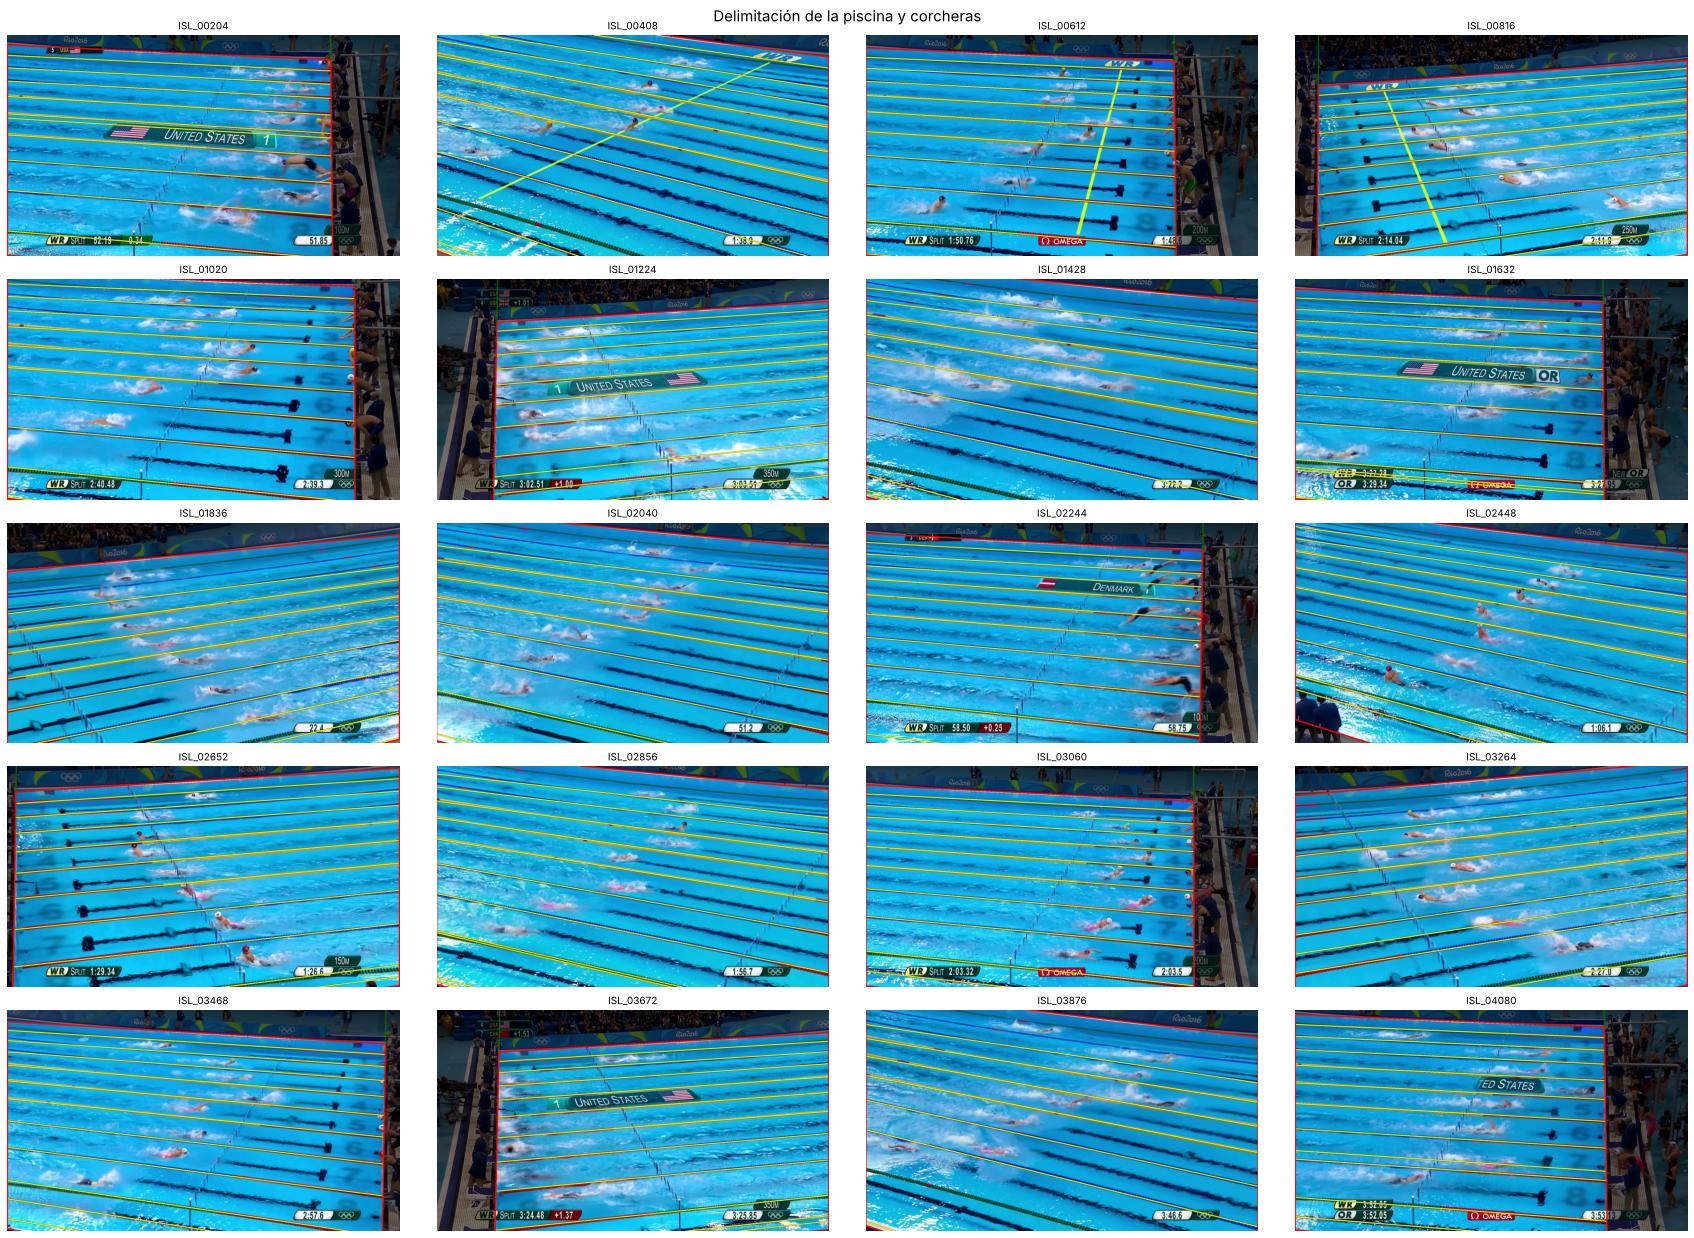

In [11]:
def grilla(funcion, titulo, columnas=4):
    nombres = list(resultados)
    filas = int(np.ceil(len(nombres) / columnas))
    fig, axs = plt.subplots(filas, columnas, figsize=(24, 3.5 * filas))
    for a, nombre in zip(axs.ravel(), nombres):
        a.imshow(rgb(funcion(imagenes[nombre], resultados[nombre]))); a.set_title(nombre, fontsize=10); a.axis("off")
    for a in axs.ravel()[len(nombres):]:
        a.axis("off")
    fig.suptitle(titulo, fontsize=15)
    plt.tight_layout(); plt.show()


grilla(vista_delimitacion, "Delimitación de la piscina y corcheras")

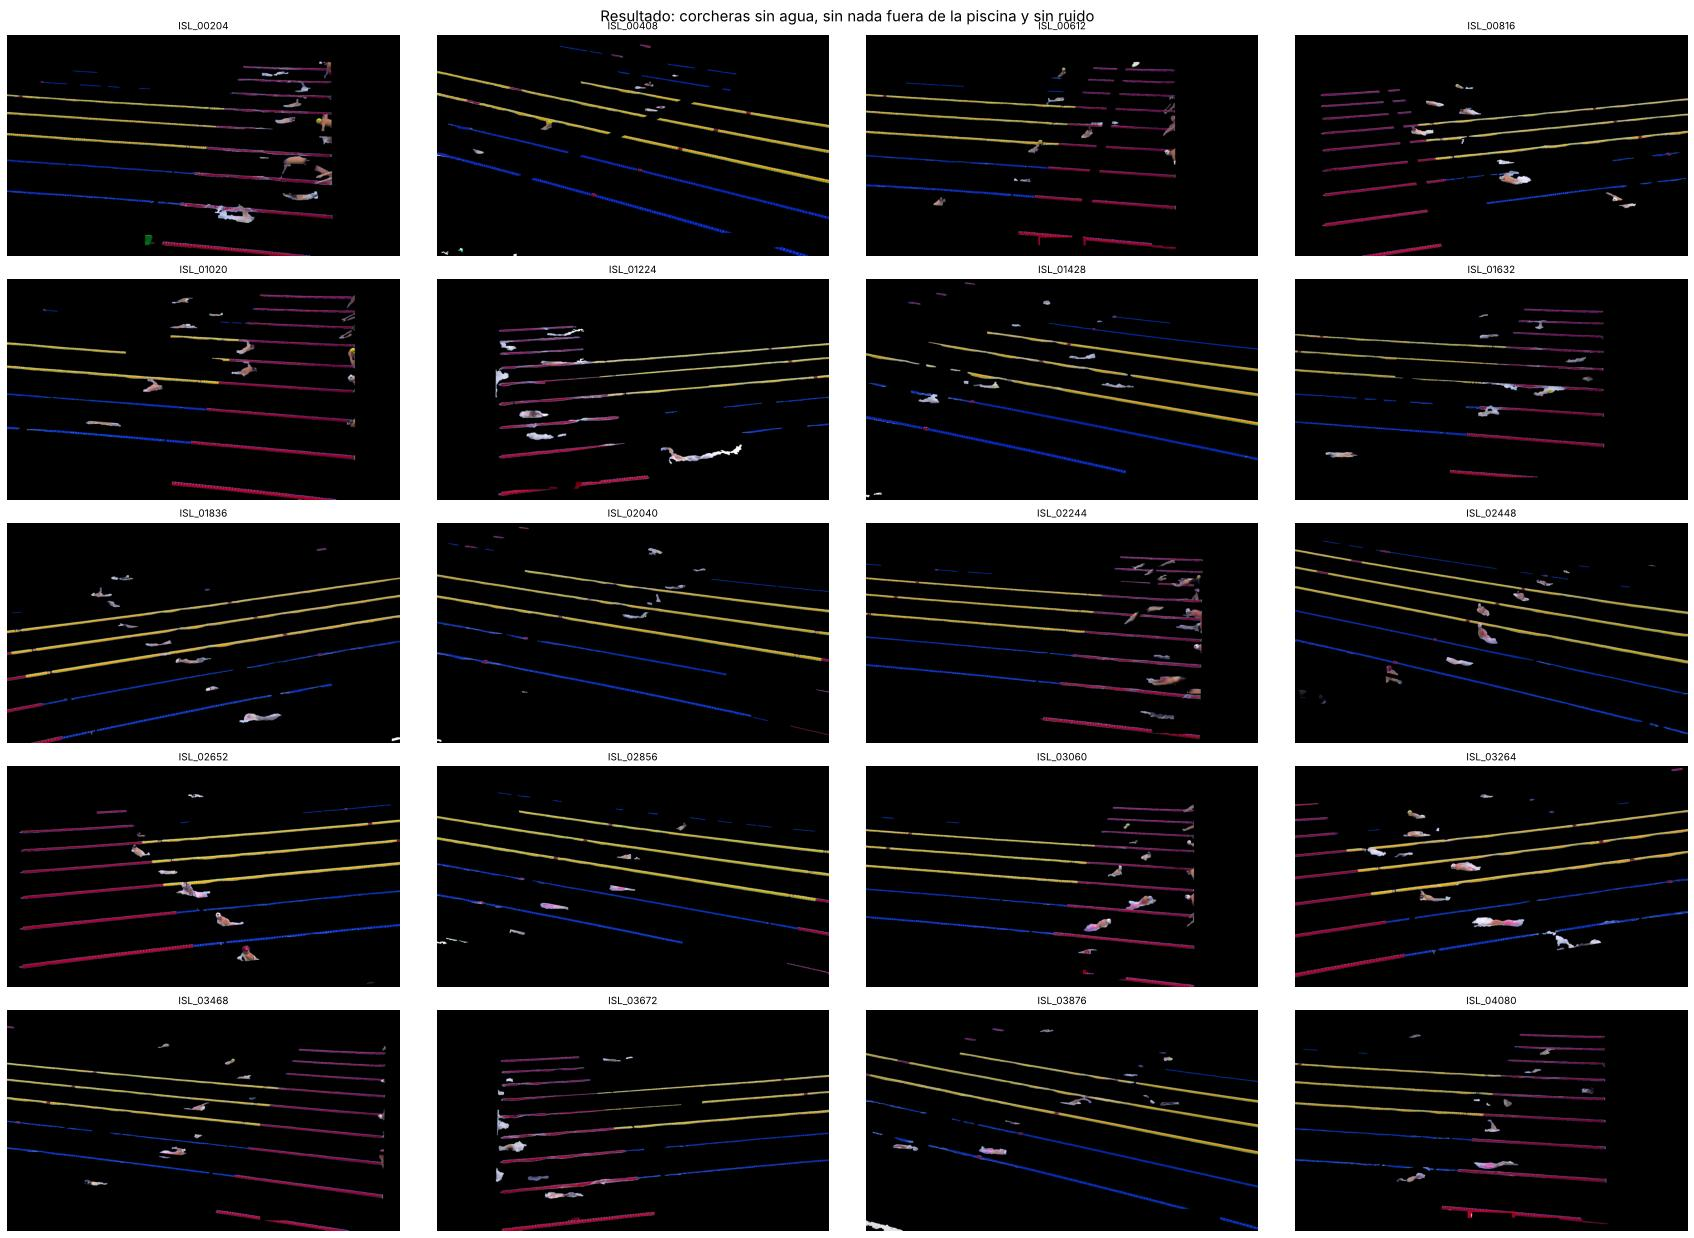

In [12]:
grilla(vista_resultado, "Resultado: corcheras sin agua, sin nada fuera de la piscina y sin ruido")

### 8.2 Guardar resultados

Por imagen, en `output/delimitacion/ISL/`: máscara de piscina, máscara de ruido y el resultado final.

In [13]:
SALIDA = ROOT / "output" / "delimitacion" / VISTA
SALIDA.mkdir(parents=True, exist_ok=True)
for nombre, res in resultados.items():
    cv2.imwrite(str(SALIDA / f"{nombre}_piscina.png"), res["piscina"])
    cv2.imwrite(str(SALIDA / f"{nombre}_ruido.png"), res["ruido"])
    cv2.imwrite(str(SALIDA / f"{nombre}_resultado.jpg"), res["resultado"], [cv2.IMWRITE_JPEG_QUALITY, 90])
print(f"{3 * len(resultados)} archivos en {SALIDA.relative_to(ROOT)}")

60 archivos en output/delimitacion/ISL


## 9. Observaciones

* **El punto de fuga es la pieza que ordena todo.** Con él, Hough deja de ser una nube de segmentos: los que apuntan al punto de fuga son corcheras, guías y bordes largos; los que no apuntan son ruido (WR, banderines, gráficos) o la pared de cabecera. Las esquinas de la piscina salen de intersectar rectas, y el punto de fuga mismo es la intersección de todas las rectas de carril.
* **Canny sobre la máscara** deja en promedio la mitad de píxeles de borde que Canny sobre gris (sección 2), y los que quedan son fronteras agua / no-agua reales. Con el gris, el oleaje genera miles de bordes que Hough convierte en segmentos espurios.
* **Rectificar** convierte un problema con perspectiva (corcheras con distinta inclinación y grosor en cada punto) en uno donde todo es horizontal: un perfil por fila encuentra las corcheras y una sola apertura horizontal las borra.
* **Gráficos de TV**: se quitan por nitidez (se renderizan nítidos, la escena real está desenfocada). Funcionó en estas 20 imágenes; en video se puede reforzar con persistencia temporal (un gráfico no se mueve con la cámara).

**Limitaciones vistas:**

* Las corcheras se detectan en las 20 imágenes (8 a 13 por imagen: alguna sale doble cuando está gruesa cerca de la cámara).
* Quedan algunas manchas pequeñas en el extremo lejano (pedazos de corchera de pocos píxeles).
* El borde cercano es la última fila con agua: en ISL la pared cercana casi nunca se ve, así que ese lado del polígono es aproximado (en `ISL_02448` deja adentro una esquina del deck con dos oficiales).
* Algo totalmente sumergido y oscuro se confunde con una guía y se borra como ruido.
* Los tamaños (80 px de hueco, 150 px de área, 25 px de margen) asumen 1920 × 1080.

**Generalizar a las otras vistas:**

* **IL / ILP**: mismo pipeline cambiando la máscara de agua (`segmentar_agua(img, "IL")` o `segmentar_ilp`). El punto de fuga queda más lejos, pero el RANSAC es el mismo.
* **IS** (cámara en planta): las corcheras son casi paralelas en la imagen y el punto de fuga sale en el infinito ($v_3 \approx 0$). Las coordenadas homogéneas ya contemplan ese caso y la rectificación se vuelve una simple rotación; cambia el filtro inicial de candidatos (verticales en lugar de casi horizontales).